# 01 · Análisis exploratorio del conjunto de datos

Objetivo (rúbrica B4): distribución de clases, desbalance detectado y estrategia para atenderlo.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import *
sns.set_theme(style="whitegrid")
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
splits = {s: pd.read_csv(SPLITS_DIR / f"{s}.csv") for s in ("train", "val", "test")}
counts = pd.DataFrame({s: d["label"].value_counts() for s, d in splits.items()}).reindex(CLASSES)
counts["total"] = counts.sum(1)
counts

,train,val,test,total
label,,,,
breakfast_burrito,643,106,250,999
ceviche,641,107,250,998
chicken_quesadilla,640,108,250,998
churros,640,108,250,998
guacamole,643,107,250,1000
huevos_rancheros,643,106,250,999
nachos,643,107,250,1000
tacos,643,107,250,1000
otro,943,157,374,1474


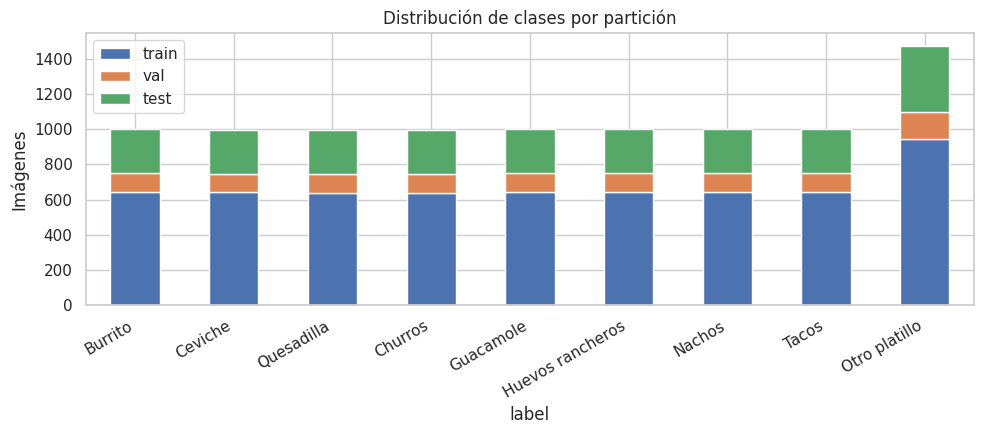

In [3]:
ax = counts[["train", "val", "test"]].rename(index=DISPLAY).plot.bar(stacked=True, figsize=(10, 4.5))
ax.set_ylabel("Imágenes"); ax.set_title("Distribución de clases por partición")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(FIG_DIR / "distribucion_clases.png", dpi=130); plt.show()

In [4]:
tr = counts["train"]
ratio = tr.max() / tr.min()
print(f"Razón de desbalance (máx/mín) en train: {ratio:.2f}")
print(f"Clase mayoritaria: {tr.idxmax()} ({tr.max()}), minoritaria: {tr.idxmin()} ({tr.min()})")

Razón de desbalance (máx/mín) en train: 1.47
Clase mayoritaria: otro (943), minoritaria: chicken_quesadilla (640)


## Desbalance y estrategia

* Food-101 es balanceado (750 train / 250 test por platillo), pero **nuestra clase `otro` es mayor** porque agrupa una muestra de 93 platillos. Además, la eliminación de casi-duplicados quita unas cuantas imágenes por clase.
* **Estrategia:** (1) pérdida de entropía cruzada **ponderada** por el inverso de la frecuencia (`src/data.py::class_weights`), (2) **aumento de datos** (recortes, color, rotación, desenfoque) y (3) métrica principal **F1 macro**, que pesa igual a todas las clases.

In [5]:
from src.data import class_weights, CLASS_TO_IDX
w = class_weights(splits["train"]["label"].map(CLASS_TO_IDX).to_numpy())
pd.Series(w.numpy(), index=CLASSES, name="peso").round(3)

,peso
breakfast_burrito,1.035
ceviche,1.038
chicken_quesadilla,1.040
churros,1.040
guacamole,1.035
huevos_rancheros,1.035
nachos,1.035
tacos,1.035
otro,0.706


## ¿Qué contiene la clase `otro`?

In [6]:
otro = splits["train"].query("label == 'otro'")["orig_class"].value_counts()
print(f"{otro.size} platillos distintos; media {otro.mean():.1f} imágenes por platillo")
otro.head(15)

93 platillos distintos; media 10.1 imágenes por platillo


,count
orig_class,
sushi,18
clam_chowder,17
bread_pudding,17
lasagna,17
chicken_curry,16
eggs_benedict,16
ice_cream,15
creme_brulee,15
scallops,15


## Muestras por clase

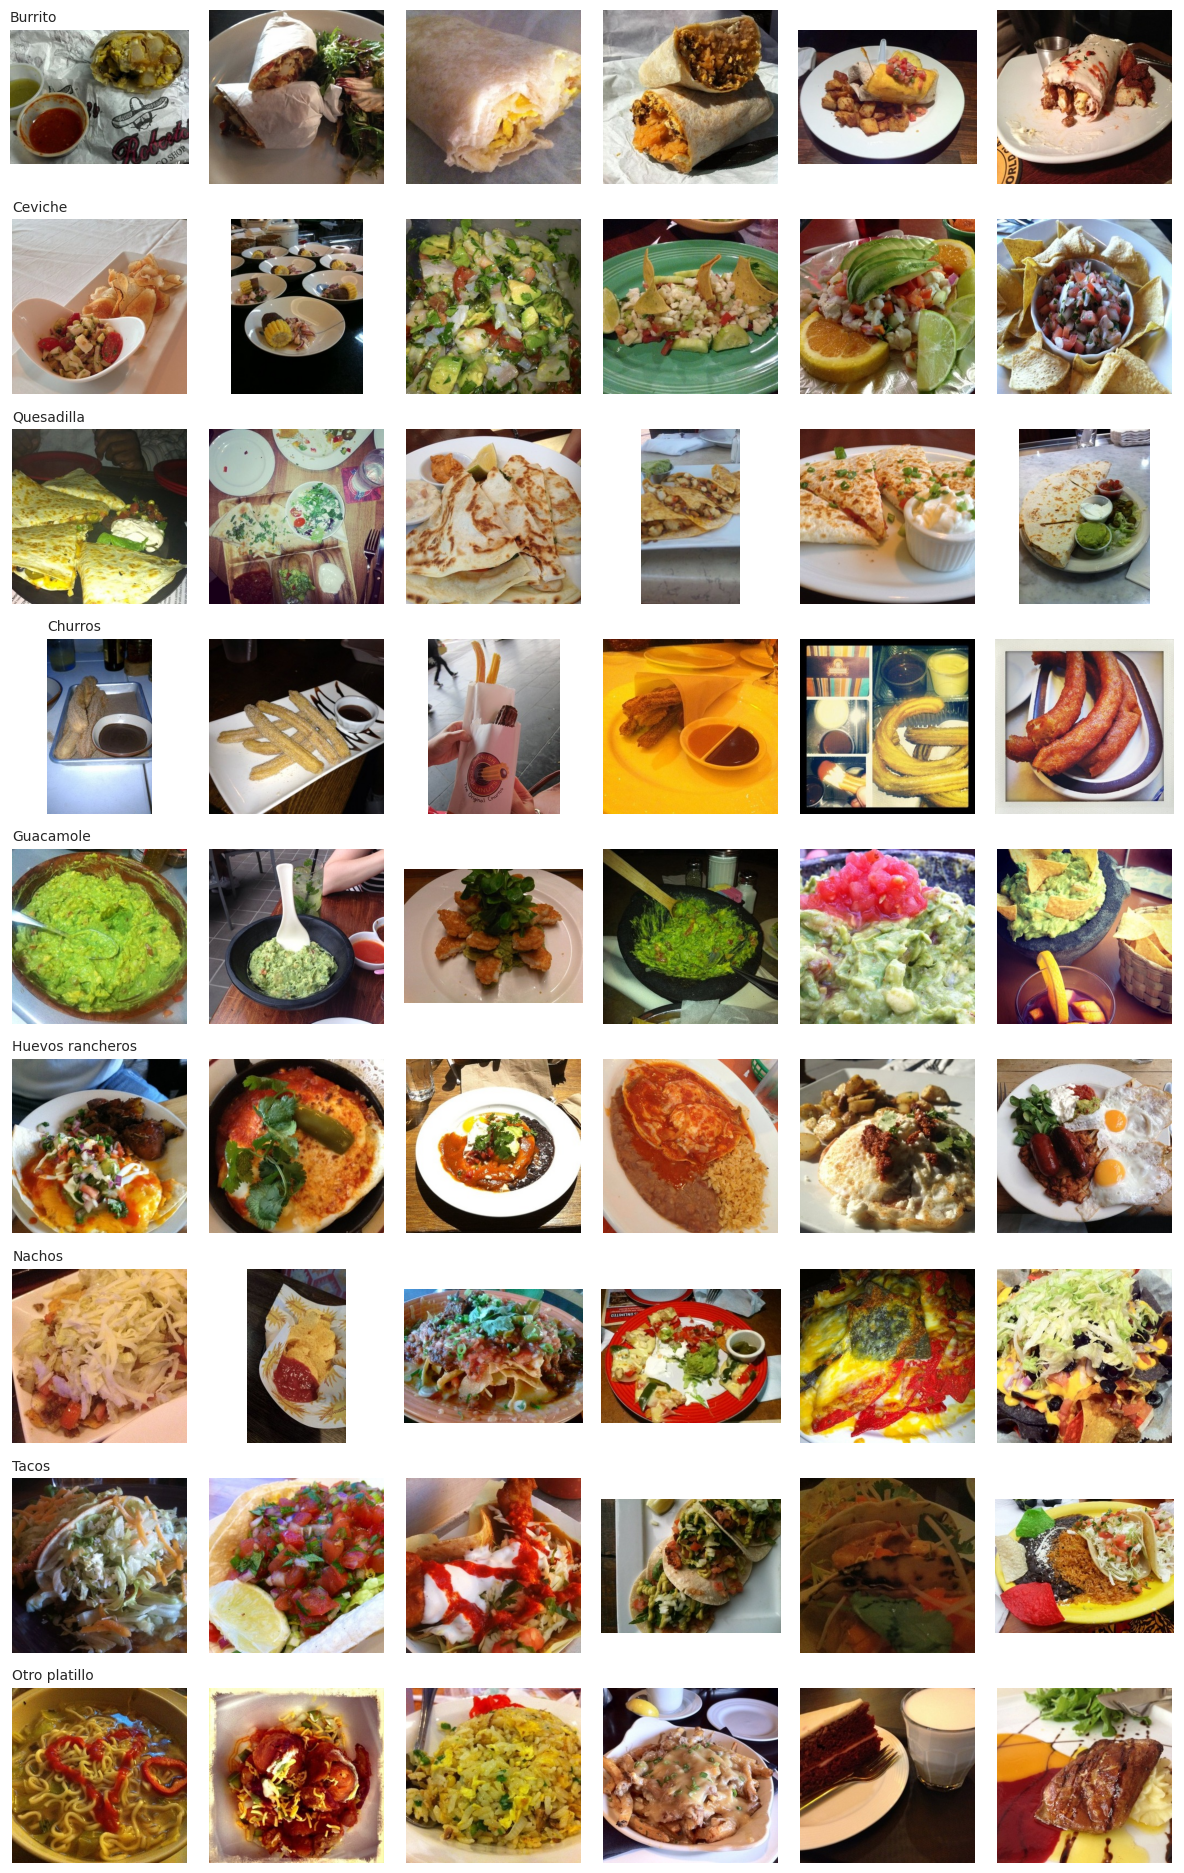

In [7]:
from PIL import Image
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 2.1 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    paths = splits["train"].query("label == @c")["path"].to_numpy()
    for j, p in enumerate(rng.choice(paths, 6, replace=False)):
        axes[i, j].imshow(Image.open(ROOT / p)); axes[i, j].axis("off")
    axes[i, 0].set_title(DISPLAY[c], loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "muestras_clases.png", dpi=90); plt.show()

## Tamaño de imagen y casi-duplicados

In [8]:
sizes = [Image.open(ROOT / p).size for p in splits["train"]["path"].sample(500, random_state=SEED)]
sizes = pd.DataFrame(sizes, columns=["ancho", "alto"])
print(sizes.describe().round(0))
rep = json.load(open(SPLITS_DIR / "reporte_particiones.json"))
print(f"\nImágenes de train casi-duplicadas de test (eliminadas): {rep['removed_train_dups_of_test']}")
print(f"Clústeres de duplicados dentro de train (asignados completos a train o val): {rep['dup_clusters_in_train']}")

       ancho   alto
count  500.0  500.0
mean   309.0  301.0
std     29.0   38.0
min    180.0  179.0
25%    320.0  320.0
50%    320.0  320.0
75%    320.0  320.0
max    320.0  320.0

Imágenes de train casi-duplicadas de test (eliminadas): 6
Clústeres de duplicados dentro de train (asignados completos a train o val): 4
